# 12. Does re-evaluation help the QoS of several priorities?

Three policies run on the same traces (notebook 10, section 5): `off`, `reeval` and
`reeval_preempt`. For every class this notebook measures what each policy changes, as **paired
differences**: the same scenario, density, condition, variant and seed with and without the
mechanism, so the mobility and the traffic are identical and only Mode 2 differs. A difference is
significant when its 95 % interval over the seeds excludes 0.

Questions:

1. How many re-evaluations and pre-emptions happen per class, and how many change a resource?
2. What do they change in QoS-PDR, collisions, DT and AoI, per priority?
3. Who pays for pre-emption: do low priorities lose what high priorities gain?
4. Which PER targets are met under each policy?
5. Can re-evaluation act on the hidden-node losses, or only on the sensing-visible ones?

In [1]:
import os, sys, json, subprocess
sys.path.insert(0, os.path.abspath("../../tools"))
sys.path.insert(0, os.path.abspath("../../tools/qos"))
import morev2x_results as mr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

mr.apply_chart_style()
os.chdir(mr.ROOT)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 160)

import plots
s = plots.Sweep()
print(s.note())
flows = s.flows.copy()
flows["policy_label"] = flows.policy.map(plots.POLICY_LABELS)

Sweep qos_smoke: 18 runs, 1 seed(s). SMOKE DATA: 4 s runs on short roads, one seed. The figures show that the pipeline works, not the results. Set QOS_SWEEP=qos_full once the full sweep is downloaded.


## 1. Checks and changes

A re-evaluation runs at T3 before every resource not yet announced, a pre-emption check at T3
before every announced one. A *change* is a check that re-selected the resource: that is the
**effective** re-evaluation (or pre-emption). Rates are per 1000 transmissions of the class.

In [2]:
counts = flows.groupby(["scenario", "policy", "name"])[["reeval_checks", "reeval_changes", "preempt_checks", "preempt_changes", "transmissions"]].sum()
rates = counts.div(counts.transmissions, axis=0).drop(columns="transmissions") * 1000
rates["effective reeval share"] = counts.reeval_changes / counts.reeval_checks.replace(0, np.nan)
rates["effective preempt share"] = counts.preempt_changes / counts.preempt_checks.replace(0, np.nan)
rates.round(3)

reeval_checks  reeval_changes  preempt_checks  preempt_changes  effective reeval share  \
scenario           policy         name                                                                                                             
highway_cpm        reeval_preempt cam                           102.434           3.548         801.250            0.000                   0.035   
                                  cooperative_perception        587.007          53.019         475.053            8.930                   0.090   
highway_platoon    off            advanced_driving              102.564           1.282           0.000            0.000                   0.012   
                                  cam                           105.559           3.608           0.000            0.000                   0.034   
                                  cooperative_perception        288.809          27.076           0.000            0.000                   0.094   
                                  crash_mitigation               13.423           0.000           0.000            0.000                   0.000   
                                  platooning                     16.856           0.208           0.000            0.000                   0.012   
                   reeval         advanced_driving              112.532           5.115           0.000            0.000                   0.045   
                                  cam                           103.969           2.673           0.000            0.000                   0.026   
                                  cooperative_perception        318.099          19.196           0.000            0.000                   0.060   
                                  crash_mitigation               26.846           0.000           0.000            0.000                   0.000   
                                  platooning                     17.073           0.416           0.000            0.000                   0.024   
                   reeval_preempt advanced_driving              101.023           2.558         886.189            0.000                   0.025   
                                  cam                           104.792           2.937         804.032            1.468                   0.028   
                                  cooperative_perception        311.151          15.288         719.424            0.899                   0.049   
                                  crash_mitigation               13.605           0.000           0.000            0.000                   0.000   
                                  platooning                     17.480           0.312         748.829            0.000                   0.018   
urban_intersection off            advanced_driving              101.852           0.000           0.000            0.000                   0.000   
                                  cam                           110.849           0.884           0.000            0.000                   0.008   
                                  cooperative_perception        275.216         145.533           0.000            0.000                   0.529   
                                  crash_mitigation               10.506           0.000           0.000            0.000                   0.000   
                                  vam                           893.112           7.126           0.000            0.000                   0.008   
                   reeval         advanced_driving               92.450           0.000           0.000            0.000                   0.000   
                                  cam                           110.259           0.590           0.000            0.000                   0.005   
                                  cooperative_perception        419.403         138.806           0.000            0.000                   0.331   
                                  crash_mitigation            

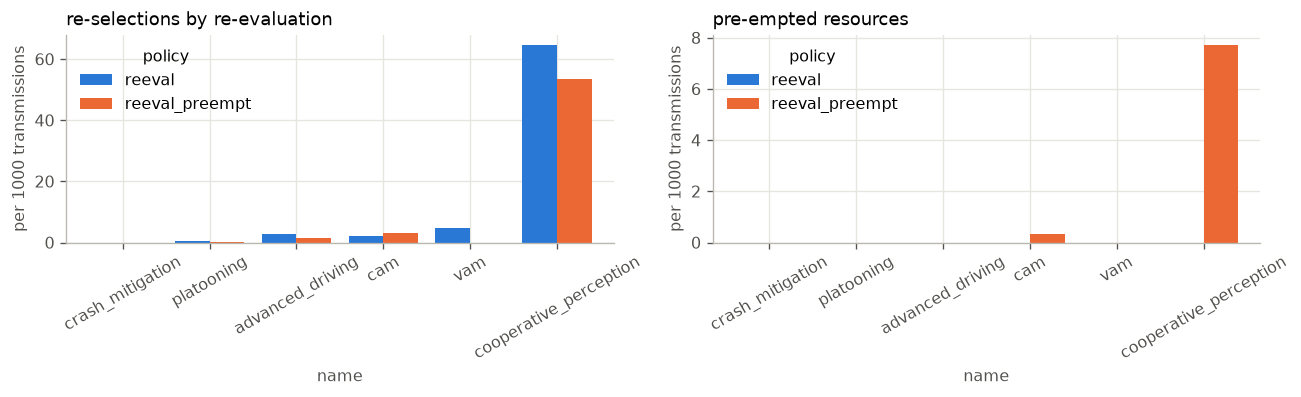

In [3]:
part = flows[flows.policy != "off"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, (value, label) in zip(axes, (("reeval_changes", "re-selections by re-evaluation"), ("preempt_changes", "pre-empted resources"))):
    t = part.groupby(["name", "policy"])[[value, "transmissions"]].sum()
    t = (1000 * t[value] / t.transmissions).unstack()
    t.reindex(plots.order_classes(t.index)).plot.bar(ax=ax, width=0.8)
    ax.set_ylabel("per 1000 transmissions"); ax.set_title(label); ax.tick_params(axis="x", rotation=30)
plt.tight_layout()

## 2. What each mechanism changes, per priority

Paired differences against `off`. Positive Δ QoS-PDR is better, negative Δ collision rate, Δ DT and
Δ AoI are better. Classes are sorted by SL priority, most important first.

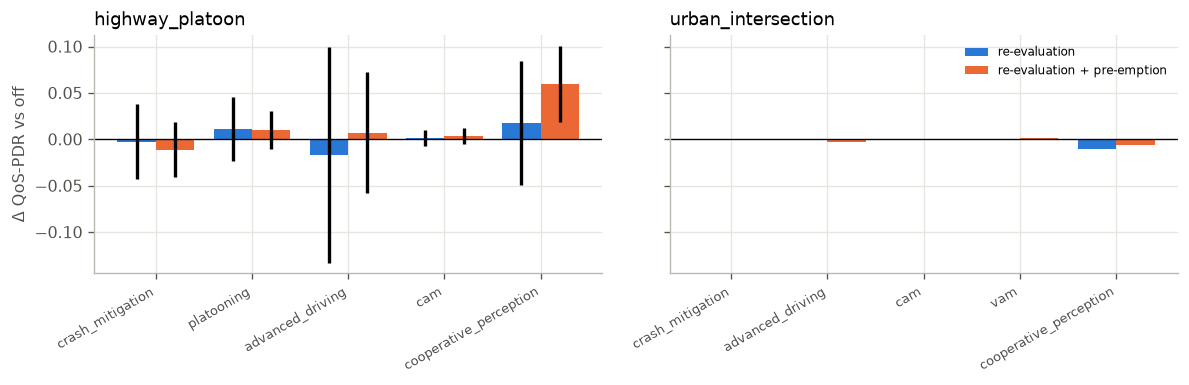

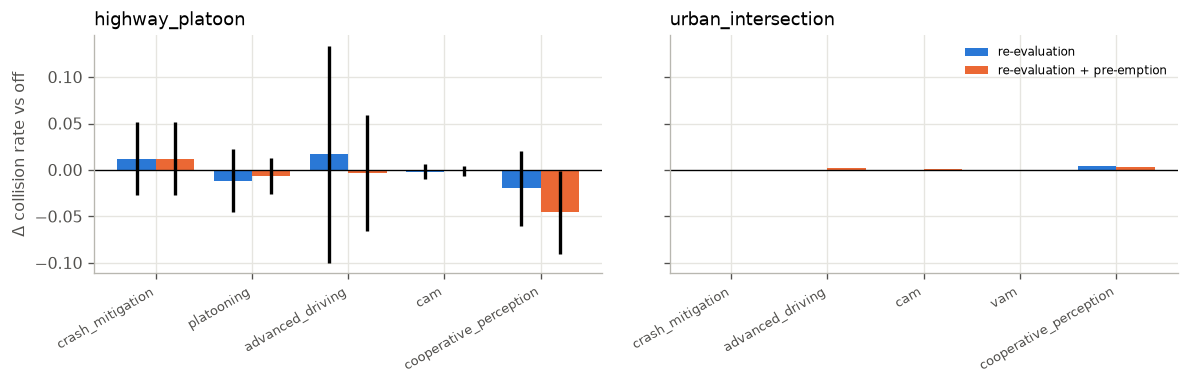

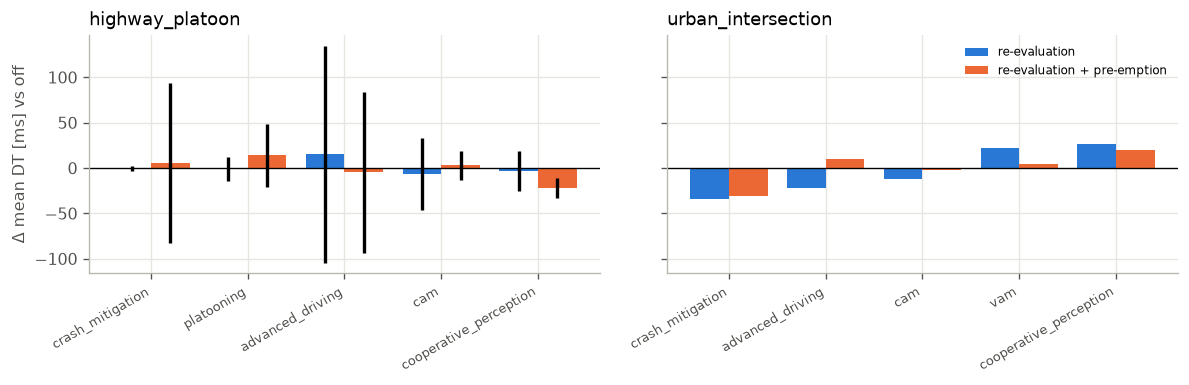

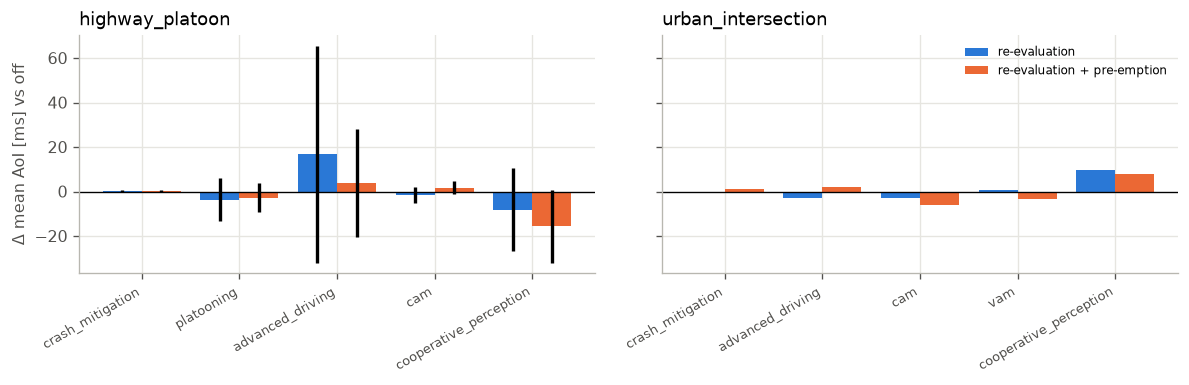

In [4]:
def delta_plot(value, label, frame=flows):
    diff = plots.paired_difference(frame, value)
    if not len(diff):
        print("no paired runs"); return None
    scenarios = sorted(diff.scenario.unique())
    fig, axes = plt.subplots(1, len(scenarios), figsize=(5 * len(scenarios), 3.3), squeeze=False, sharey=True)
    for ax, scenario in zip(axes[0], scenarios):
        part = diff[diff.scenario == scenario]
        names = plots.order_classes(part.name.unique())
        for k, policy in enumerate(["reeval", "reeval_preempt"]):
            stats = plots.mean_ci(part[part.policy == policy], "delta", "name").set_index("name").reindex(names)
            ax.bar(np.arange(len(names)) + 0.4 * k - 0.2, stats["mean"], 0.4, yerr=stats["ci"], label=plots.POLICY_LABELS[policy])
        ax.axhline(0, color="black", lw=0.8)
        ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=30, ha="right", fontsize=8); ax.set_title(scenario)
    axes[0][0].set_ylabel("Δ " + label + " vs off"); axes[0][-1].legend(fontsize=7)
    plt.tight_layout()
    return diff

d_pdr = delta_plot("qos_pdr", "QoS-PDR")
d_col = delta_plot("collision_rate", "collision rate")
d_dt = delta_plot("dt_mean_ms", "mean DT [ms]")
d_aoi = delta_plot("aoi_mean_ms", "mean AoI [ms]")

The same differences as a table, with the interval and whether it excludes 0:

In [5]:
rows = []
for value, diff in (("qos_pdr", d_pdr), ("collision_rate", d_col), ("dt_mean_ms", d_dt), ("aoi_mean_ms", d_aoi)):
    if diff is None:
        continue
    stats = plots.mean_ci(diff, "delta", ["scenario", "policy", "name"])
    stats["metric"] = value
    rows.append(stats)
table = pd.concat(rows)
table["significant"] = (table["mean"].abs() > table["ci"]) & table["ci"].notna()
table.pivot_table(index=["scenario", "name"], columns=["metric", "policy"], values="mean").round(4)

metric                                    aoi_mean_ms                collision_rate                dt_mean_ms                qos_pdr               
policy                                         reeval reeval_preempt         reeval reeval_preempt     reeval reeval_preempt  reeval reeval_preempt
scenario           name                                                                                                                            
highway_platoon    advanced_driving           16.7205         3.8381         0.0168        -0.0031    15.2284        -4.5341 -0.0165         0.0072
                   cam                        -1.5289         1.7056        -0.0017        -0.0014    -6.5402         3.2251  0.0013         0.0037
                   cooperative_perception     -8.2292       -15.7323        -0.0199        -0.0453    -3.1741       -22.2210  0.0176         0.0596
                   crash_mitigation            0.2774         0.1849         0.0123         0.0123    -0.1500         5.5667 -0.0025        -0.0115
                   platooning                 -3.7141        -2.7353        -0.0114        -0.0069    -0.6815        14.0738  0.0109         0.0097
urban_intersection advanced_driving           -2.8964         1.8197         0.0003         0.0025   -21.8157        10.5912 -0.0000        -0.0032
                   cam                        -3.1452        -6.1475         0.0005         0.0008   -12.2534        -2.4386  0.0004        -0.0001
                   cooperative_perception      9.6606         7.8929         0.0042         0.0027    26.4083        19.6357 -0.0100        -0.0062
                   crash_mitigation           -0.5709         0.9966         0.0000         0.0004   -33.9376       -30.2049 -0.0007        -0.0008
                   vam                         0.6468        -3.1504        -0.0002        -0.0004    22.3156         4.4248  0.0000         0.0016

## 3. Who pays for pre-emption

Pre-emption moves a lower-priority resource out of the way of a higher-priority reservation. If it
works as intended, the gain of the important classes is larger than the loss of the less important
ones. Below, Δ QoS-PDR of `reeval_preempt` against `reeval`, the effect of pre-emption alone,
against the SL priority of the class.

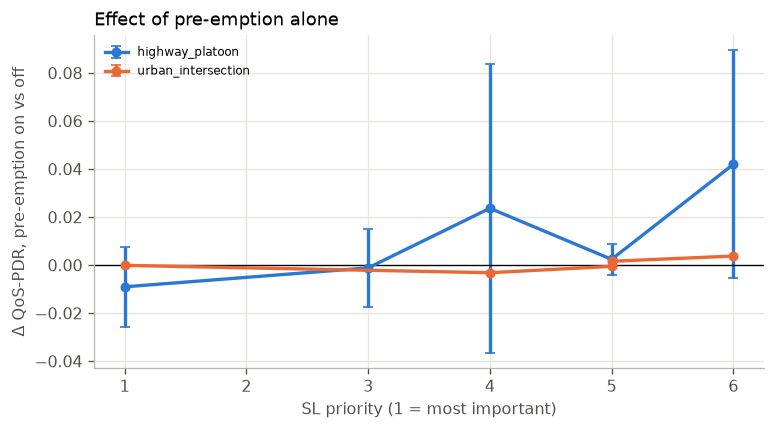

In [6]:
diff = plots.paired_difference(flows, "qos_pdr", baseline="reeval")
diff = diff[diff.policy == "reeval_preempt"]
if len(diff):
    priority = flows.drop_duplicates("name").set_index("name").priority
    diff["priority"] = diff.name.map(priority)
    stats = plots.mean_ci(diff, "delta", ["scenario", "priority", "name"])
    for scenario, g in stats.groupby("scenario"):
        plt.errorbar(g.priority, g["mean"], yerr=g["ci"], marker="o", capsize=3, label=scenario)
    plt.axhline(0, color="black", lw=0.8); plt.xlabel("SL priority (1 = most important)")
    plt.ylabel("Δ QoS-PDR, pre-emption on vs off"); plt.legend(fontsize=7); plt.title("Effect of pre-emption alone")

## 4. PER targets met

A cell is the share of runs in which the measured PER (1 − QoS-PDR over all attempts up to
1000 m) is at or below the PQI target. Most targets are far out of reach without retransmissions,
so the second table shows how many times above its target each class stays.

In [7]:
met = flows.groupby(["scenario", "name", "policy"]).per_met.mean().unstack()
met.reindex(columns=[p for p in plots.POLICY_ORDER if p in met.columns]).round(2)

policy                                      off  reeval  reeval_preempt
scenario           name                                                
highway_cpm        cam                      NaN     NaN            0.00
                   cooperative_perception   NaN     NaN            0.00
highway_platoon    advanced_driving        0.00    0.00            0.00
                   cam                     0.00    0.00            0.00
                   cooperative_perception  0.00    0.00            0.00
                   crash_mitigation        0.25    0.25            0.25
                   platooning              0.00    0.00            0.00
urban_intersection advanced_driving        0.00    0.00            0.00
                   cam                     0.00    0.00            0.00
                   cooperative_perception  0.00    0.00            0.00
                   crash_mitigation        0.00    0.00            0.00
                   vam                     0.00    0.00            0.00

In [8]:
flows["per_ratio"] = flows.per_measured / flows.per_target
ratio = flows.groupby(["scenario", "name", "policy"]).per_ratio.mean().unstack()
ratio.reindex(columns=[p for p in plots.POLICY_ORDER if p in ratio.columns]).round(1)

policy                                         off   reeval  reeval_preempt
scenario           name                                                    
highway_cpm        cam                         NaN      NaN           578.1
                   cooperative_perception      NaN      NaN            36.8
highway_platoon    advanced_driving            6.9      8.5             6.1
                   cam                       381.4    368.5           344.2
                   cooperative_perception     27.4     25.7            21.5
                   crash_mitigation         3524.6   3770.5          4672.1
                   platooning                296.9    188.2           199.5
urban_intersection advanced_driving           74.7     74.7            75.0
                   cam                      7340.8   7337.0          7341.9
                   cooperative_perception     78.5     79.5            79.1
                   crash_mitigation        70777.7  70850.5         70859.6
                   vam                      7000.1   7000.1          6984.0

## 5. Hidden-node losses against sensing-visible ones

Re-evaluation and pre-emption only use what the UE sensed. They cannot help against interferers the
sender never decoded. Splitting the collision losses shows which part moved.

In [9]:
c = s.causes[s.causes.cause.isin(["hidden-node collision", "sensing-visible collision"])]
t = c.groupby(["scenario", "policy", "cause"])["count"].sum().unstack()
attempts = s.by_distance.groupby(["scenario", "policy"]).attempts.sum()
(t.div(attempts, axis=0)).unstack("policy").round(5)

cause              hidden-node collision                         sensing-visible collision                        
policy                               off   reeval reeval_preempt                       off   reeval reeval_preempt
scenario                                                                                                          
highway_cpm                          NaN      NaN        0.00064                       NaN      NaN        0.08101
highway_platoon                  0.00023  0.00014        0.00018                   0.02145  0.01435        0.01172
urban_intersection               0.00272  0.00330        0.00383                   0.00049  0.00095        0.00069

## 6. Under impairments

Does re-evaluation help more, or less, when the channel is jammed, bursty, or the budget shorter?
Δ QoS-PDR of the platooning class, per condition.

In [10]:
platoon = flows[(flows.scenario == "highway_platoon") & (flows.name == "platooning")]
diff = plots.paired_difference(platoon, "qos_pdr")
if len(diff):
    stats = plots.mean_ci(diff, "delta", ["condition", "policy", "density"])
    stats.pivot_table(index=["condition", "density"], columns="policy", values="mean").round(4)

## 7. Reading the results

The cells above answer the questions with the numbers of the sweep shown. Keep in mind when
concluding:

* With one seed (smoke sweep) there is no interval and no conclusion.
* Δ QoS-PDR of a class is bounded by its sensing-visible collision losses under `off`: if those
  are small, nothing can improve much.
* A class that is dynamic (crash mitigation, emergency trajectory) is never pre-empted and never
  pre-empts: its own resources are not announced, and it announces nothing.
* Pre-emption re-selects with the remaining budget only, which for 20 ms platooning at T3 = 2.25 ms
  before the resource leaves a short window.